In [3]:
import pandas as pd

df = pd.read_csv("C:\\Users\\Shravani\\Desktop\\uber-raw-data-apr14.csv")

print(df.head())
print(df.columns)
print(df["Date/Time"].isnull().sum())
print(df.shape)

          Date/Time      Lat      Lon    Base
0  4/1/2014 0:11:00  40.7690 -73.9549  B02512
1  4/1/2014 0:17:00  40.7267 -74.0345  B02512
2  4/1/2014 0:21:00  40.7316 -73.9873  B02512
3  4/1/2014 0:28:00  40.7588 -73.9776  B02512
4  4/1/2014 0:33:00  40.7594 -73.9722  B02512
Index(['Date/Time', 'Lat', 'Lon', 'Base'], dtype='object')
0
(564516, 4)


In [4]:
df["Date/Time"] = pd.to_datetime(df["Date/Time"])

print(df.dtypes)

Date/Time    datetime64[ns]
Lat                 float64
Lon                 float64
Base                 object
dtype: object


In [5]:
df.isnull()

,Date/Time,Lat,Lon,Base
0,False,False,False,False
1,False,False,False,False
2,False,False,False,False
3,False,False,False,False
4,False,False,False,False
...,...,...,...,...
564511,False,False,False,False
564512,False,False,False,False
564513,False,False,False,False
564514,False,False,False,False


In [6]:
df.isnull().sum()

Date/Time    0
Lat          0
Lon          0
Base         0
dtype: int64

In [7]:
print("start date",df["Date/Time"].min())
print("End date",df["Date/Time"].max())

start date 2014-04-01 00:00:00
End date 2014-04-30 23:59:00


In [8]:
df["Base"].value_counts()

Base
B02682    227808
B02598    183263
B02617    108001
B02512     35536
B02764      9908
Name: count, dtype: int64

In [9]:
df.duplicated()

0         False
1         False
2         False
3         False
4         False
          ...  
564511    False
564512    False
564513    False
564514    False
564515    False
Length: 564516, dtype: bool

In [10]:
df.duplicated().sum()

7749

In [11]:
df[df.duplicated(keep=False)].head(10)

,Date/Time,Lat,Lon,Base
43,2014-04-01 05:44:00,40.7430,-74.0301,B02512
44,2014-04-01 05:44:00,40.7430,-74.0301,B02512
127,2014-04-01 07:25:00,40.7805,-73.9481,B02512
128,2014-04-01 07:25:00,40.7805,-73.9481,B02512
184,2014-04-01 08:25:00,40.7620,-73.9787,B02512
185,2014-04-01 08:25:00,40.7620,-73.9787,B02512
189,2014-04-01 08:29:00,40.6904,-74.1778,B02512
190,2014-04-01 08:29:00,40.6904,-74.1778,B02512
237,2014-04-01 09:49:00,40.7195,-74.0367,B02512
238,2014-04-01 09:49:00,40.7195,-74.0367,B02512


In [12]:
df=df.drop_duplicates()

In [13]:
df.duplicated().sum()

0

In [14]:
df = pd.read_csv("C:\\Users\\Shravani\\Desktop\\uber-raw-data-apr14.csv")

df["Date/Time"] = pd.to_datetime(df["Date/Time"])

In [15]:
df_original = df.copy()

In [16]:
df_cleaned = df.drop_duplicates()

In [17]:
print("Original:", df_original.shape)
print("Cleaned:", df_cleaned.shape)

Original: (564516, 4)
Cleaned: (556767, 4)


In [18]:
df_cleaned["Lat"].describe()

count    556767.000000
mean         40.739973
std           0.036027
min          40.072900
25%          40.722500
50%          40.742500
75%          40.760700
max          42.116600
Name: Lat, dtype: float64

In [19]:
df_cleaned["Lon"].describe()

count    556767.000000
mean        -73.976799
std           0.050330
min         -74.773300
25%         -73.997700
50%         -73.984700
75%         -73.969900
max         -72.066600
Name: Lon, dtype: float64

In [20]:
Q1 = df_cleaned["Lat"].quantile(0.25)
Q3 = df_cleaned["Lat"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("IQR:", IQR)
print("Lower:", lower)
print("Upper:", upper)

IQR: 0.03820000000000334
Lower: 40.66519999999999
Upper: 40.818000000000005


In [21]:
lat_outliers = df_cleaned[
    (df_cleaned["Lat"] < lower) |
    (df_cleaned["Lat"] > upper)
]

print(lat_outliers.shape)

(26084, 4)


In [22]:
Q1 = df_cleaned["Lon"].quantile(0.25)
Q3 = df_cleaned["Lon"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("IQR:", IQR)
print("Lower:", lower)
print("Upper:", upper)

IQR: 0.02779999999999916
Lower: -74.0394
Upper: -73.9282


In [23]:
lon_outliers = df_cleaned[
    (df_cleaned["Lon"] < lower) |
    (df_cleaned["Lon"] > upper)
]

print(lon_outliers.shape)

(44934, 4)


In [24]:
df_cleaned.nsmallest(10, "Lat")

,Date/Time,Lat,Lon,Base
247368,2014-04-08 14:11:00,40.0729,-74.1638,B02617
378022,2014-04-07 10:31:00,40.1918,-74.6036,B02682
489976,2014-04-23 16:02:00,40.2026,-74.1224,B02682
268282,2014-04-14 18:43:00,40.2168,-74.5670,B02617
43493,2014-04-02 21:44:00,40.2259,-74.6235,B02598
12225,2014-04-10 18:06:00,40.2549,-74.7039,B02512
341517,2014-04-03 07:16:00,40.2643,-74.3553,B02682
370437,2014-04-06 00:24:00,40.2678,-74.5440,B02682
260142,2014-04-11 21:29:00,40.2825,-74.1419,B02617
332536,2014-04-01 21:35:00,40.3082,-74.1148,B02682


In [25]:
df_cleaned.nlargest(10, "Lat")

,Date/Time,Lat,Lon,Base
137573,2014-04-20 08:32:00,42.1166,-72.0666,B02598
505041,2014-04-25 10:49:00,41.5276,-72.7734,B02682
506318,2014-04-25 14:54:00,41.5016,-72.8987,B02682
388457,2014-04-08 16:34:00,41.3737,-73.7988,B02682
30945,2014-04-28 05:49:00,41.3730,-72.9237,B02512
106170,2014-04-14 20:50:00,41.3469,-73.9544,B02598
465907,2014-04-19 12:45:00,41.3199,-73.9901,B02682
63746,2014-04-06 12:40:00,41.3197,-73.6903,B02598
482643,2014-04-22 15:39:00,41.3056,-72.9299,B02682
459506,2014-04-18 14:06:00,41.3000,-74.1847,B02682


In [26]:
df_cleaned.nsmallest(10, "Lon")

,Date/Time,Lat,Lon,Base
441842,2014-04-16 06:10:00,40.6395,-74.7733,B02682
443245,2014-04-16 10:26:00,40.6392,-74.7659,B02682
12225,2014-04-10 18:06:00,40.2549,-74.7039,B02512
524899,2014-04-27 15:14:00,40.3488,-74.6631,B02682
127867,2014-04-18 14:25:00,40.3343,-74.6563,B02598
379715,2014-04-07 16:14:00,40.5717,-74.6561,B02682
531507,2014-04-28 18:35:00,40.5715,-74.6559,B02682
389026,2014-04-08 17:38:00,40.5716,-74.6558,B02682
345382,2014-04-03 17:19:00,40.5716,-74.6557,B02682
497367,2014-04-24 14:38:00,40.5716,-74.6557,B02682


In [27]:
df_cleaned.nlargest(10, "Lon")

,Date/Time,Lat,Lon,Base
137573,2014-04-20 08:32:00,42.1166,-72.0666,B02598
276498,2014-04-17 03:49:00,40.9162,-72.7006,B02617
277001,2014-04-17 08:00:00,40.9162,-72.7006,B02617
505041,2014-04-25 10:49:00,41.5276,-72.7734,B02682
506318,2014-04-25 14:54:00,41.5016,-72.8987,B02682
30945,2014-04-28 05:49:00,41.3730,-72.9237,B02512
515060,2014-04-26 12:09:00,41.2981,-72.9265,B02682
482643,2014-04-22 15:39:00,41.3056,-72.9299,B02682
190247,2014-04-27 19:51:00,41.2339,-73.0405,B02598
425005,2014-04-13 13:32:00,40.8587,-73.0791,B02682


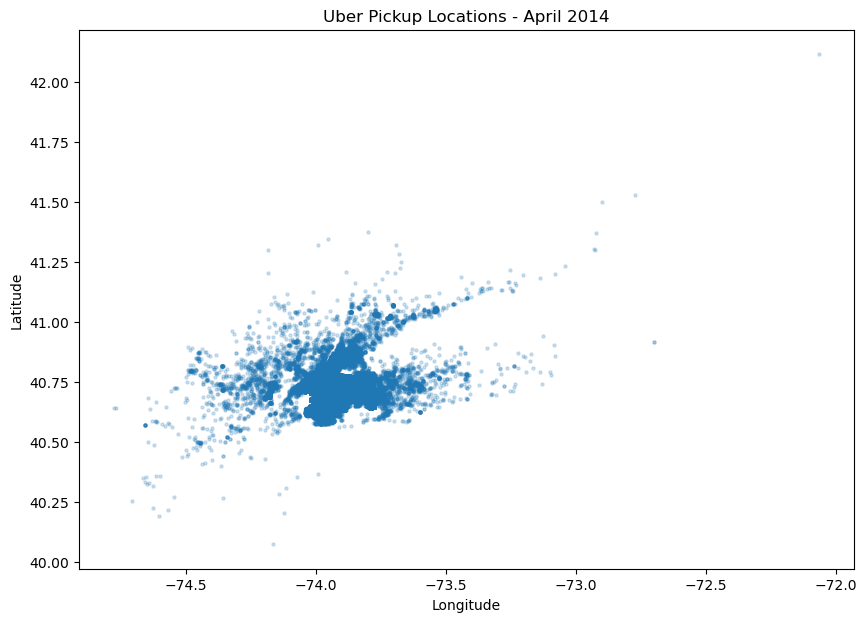

In [29]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 7))

plt.scatter(
    df_cleaned["Lon"],
    df_cleaned["Lat"],
    alpha=0.2,
    s=5
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Uber Pickup Locations - April 2014")

plt.show()

In [36]:
df_cleaned = df.drop_duplicates().copy()

In [38]:
df_cleaned["Hour"] = df_cleaned["Date/Time"].dt.hour

In [39]:
df_cleaned["Day"] = df_cleaned["Date/Time"].dt.day

df_cleaned["Day_Name"] = df_cleaned["Date/Time"].dt.day_name()

df_cleaned["Month"] = df_cleaned["Date/Time"].dt.month

df_cleaned["Year"] = df_cleaned["Date/Time"].dt.year

In [40]:
df_cleaned.head()

,Date/Time,Lat,Lon,Base,Hour,Day,Day_Name,Month,Year
0,2014-04-01 00:11:00,40.7690,-73.9549,B02512,0,1,Tuesday,4,2014
1,2014-04-01 00:17:00,40.7267,-74.0345,B02512,0,1,Tuesday,4,2014
2,2014-04-01 00:21:00,40.7316,-73.9873,B02512,0,1,Tuesday,4,2014
3,2014-04-01 00:28:00,40.7588,-73.9776,B02512,0,1,Tuesday,4,2014
4,2014-04-01 00:33:00,40.7594,-73.9722,B02512,0,1,Tuesday,4,2014


In [41]:
hourly_trips = df_cleaned["Hour"].value_counts().sort_index()

print(hourly_trips)

Hour
0     11716
1      7620
2      4849
3      4938
4      5965
5      9302
6     18224
7     24624
8     22577
9     17758
10    17660
11    18545
12    19179
13    22329
14    26851
15    34835
16    41408
17    44888
18    42439
19    38380
20    35729
21    36427
22    30189
23    20335
Name: count, dtype: int64


In [42]:
print("Busiest Hour:", hourly_trips.idxmax())

print("Maximum Pickups:", hourly_trips.max())

Busiest Hour: 17
Maximum Pickups: 44888


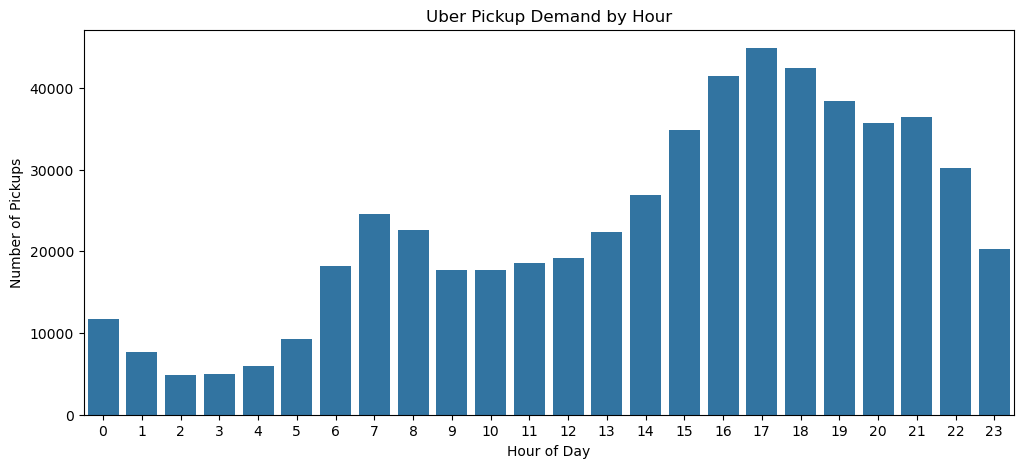

In [44]:
import seaborn as sns
plt.figure(figsize=(12, 5))

sns.barplot(
    x=hourly_trips.index,
    y=hourly_trips.values
)

plt.title("Uber Pickup Demand by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Pickups")
plt.xticks(range(24))
plt.show()

In [45]:
daily_trips = df_cleaned["Day_Name"].value_counts()

print(daily_trips)

Day_Name
Wednesday    107120
Tuesday       89957
Friday        88985
Thursday      83954
Saturday      76152
Monday        60075
Sunday        50524
Name: count, dtype: int64


In [46]:
print("Busiest Day:", daily_trips.idxmax())
print("Maximum Pickups:", daily_trips.max())

Busiest Day: Wednesday
Maximum Pickups: 107120


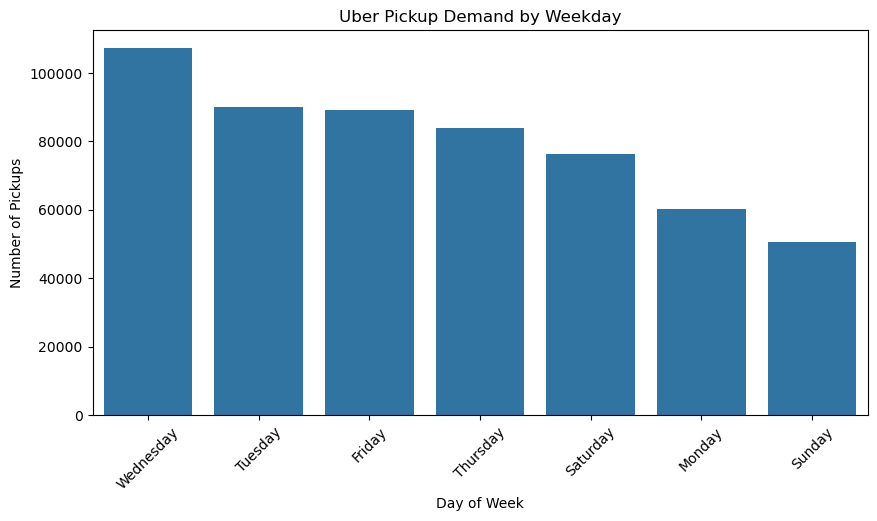

In [47]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=daily_trips.index,
    y=daily_trips.values
)

plt.title("Uber Pickup Demand by Weekday")
plt.xlabel("Day of Week")
plt.ylabel("Number of Pickups")
plt.xticks(rotation=45)

plt.show()

In [48]:
date_trips = df_cleaned["Day"].value_counts().sort_index()

print(date_trips)

Day
1     14376
2     17230
3     20482
4     26353
5     19273
6     13248
7     19319
8     15996
9     16631
10    19785
11    20137
12    17920
13    11948
14    12511
15    20359
16    17494
17    20695
18    17804
19    14394
20    10876
21    12975
22    16710
23    20047
24    22992
25    24691
26    24565
27    14452
28    15270
29    22516
30    35718
Name: count, dtype: int64


In [49]:
print("Busiest Date:", date_trips.idxmax())
print("Maximum Pickups:", date_trips.max())

Busiest Date: 30
Maximum Pickups: 35718


In [59]:
base_trips = df_cleaned["Base"].value_counts()

print(base_trips)

Base
B02682    225569
B02598    181891
B02617    105141
B02512     34258
B02764      9908
Name: count, dtype: int64


In [60]:
print("Top Base:", base_trips.idxmax())
print("Total Pickups:", base_trips.max())

Top Base: B02682
Total Pickups: 225569


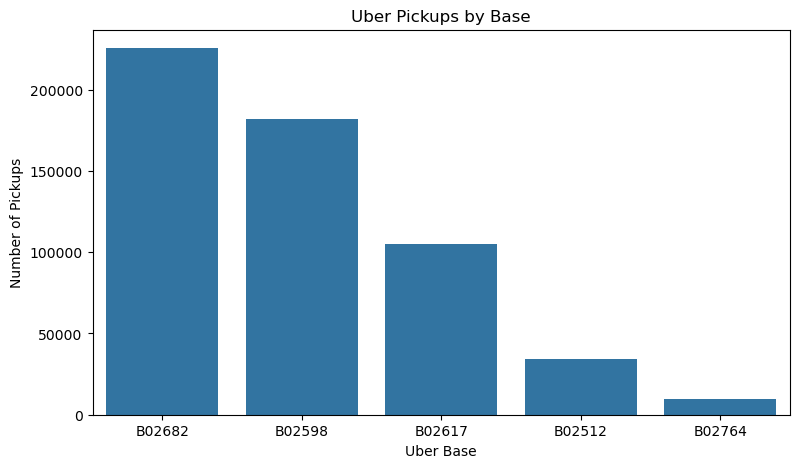

In [61]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=base_trips.index,
    y=base_trips.values
)

plt.title("Uber Pickups by Base")
plt.xlabel("Uber Base")
plt.ylabel("Number of Pickups")

plt.show()

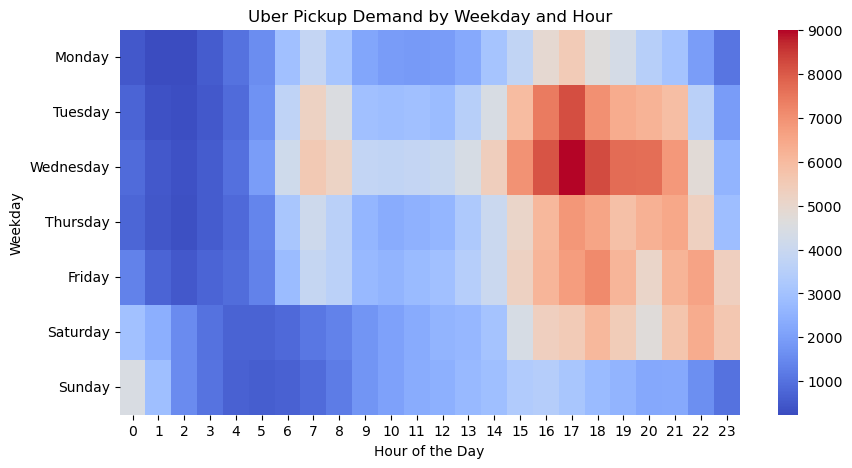

In [62]:
weekday_hour = pd.crosstab(
    df_cleaned["Day_Name"],
    df_cleaned["Hour"]
)

days_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekday_hour = weekday_hour.reindex(days_order)

plt.figure(figsize=(10, 5))
sns.heatmap(weekday_hour, cmap="coolwarm")

plt.title("Uber Pickup Demand by Weekday and Hour")
plt.xlabel("Hour of the Day")
plt.ylabel("Weekday")
plt.show()

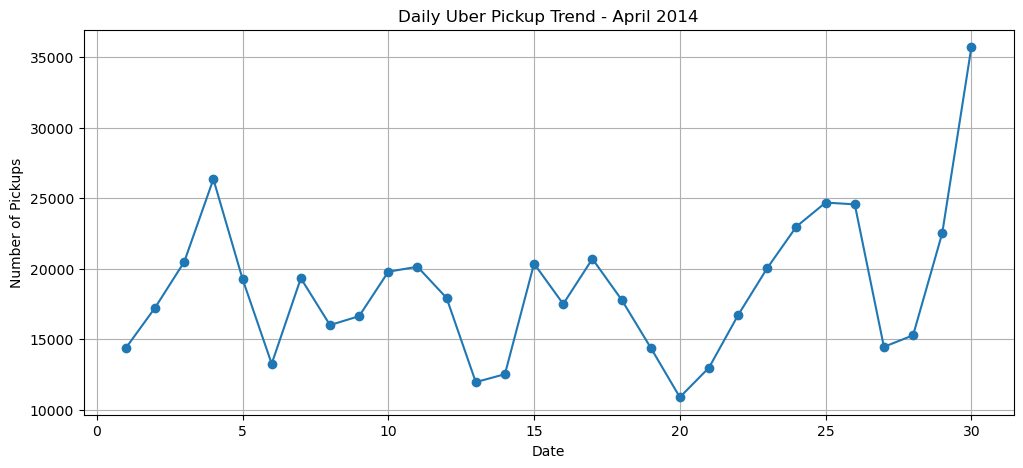

In [63]:
plt.figure(figsize=(12, 5))

plt.plot(date_trips.index, date_trips.values, marker="o")

plt.title("Daily Uber Pickup Trend - April 2014")
plt.xlabel("Date")
plt.ylabel("Number of Pickups")

plt.grid()
plt.show()